In [1]:
pip install pandas-datareader


Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install --upgrade pandas-datareader

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import datetime as dt
import yfinance as yf  # Changed from pandas_datareader
import plotly.express as px
import plotly.graph_objects as go

In [8]:
# Data
start = dt.datetime(2019,1,1)
end = dt.datetime.now()

# Define the tickers (Note: 'FB' is now 'META')
tickers = ['META', 'AMZN', 'AAPL', 'NFLX', 'GOOGL', 'MSFT']

# Download all data
stocks = yf.download(tickers, start=start, end=end)

# Create the stocks_close DataFrame specifically
stocks_close = stocks['Close']

[*********************100%***********************]  6 of 6 completed


In [9]:
stocks_close

Ticker,AAPL,AMZN,GOOGL,META,MSFT,NFLX
Date,,,,,,
2019-01-02,37.503723,76.956497,52.338547,134.738800,94.397148,26.766001
2019-01-03,33.768082,75.014000,50.889000,130.826126,90.924446,27.120001
2019-01-04,35.209606,78.769501,53.499271,136.993073,95.153313,29.757000
2019-01-07,35.131245,81.475502,53.392586,137.092361,95.274658,31.534000
2019-01-08,35.800961,82.829002,53.861538,141.541290,95.965454,32.027000
...,...,...,...,...,...,...
2026-02-25,274.230011,210.639999,312.899994,653.690002,400.600006,82.699997
2026-02-26,272.950012,207.919998,307.380005,657.010010,401.720001,84.589996
2026-02-27,264.179993,210.000000,311.760010,648.179993,392.739990,96.239998


[*********************100%***********************]  1 of 1 completed


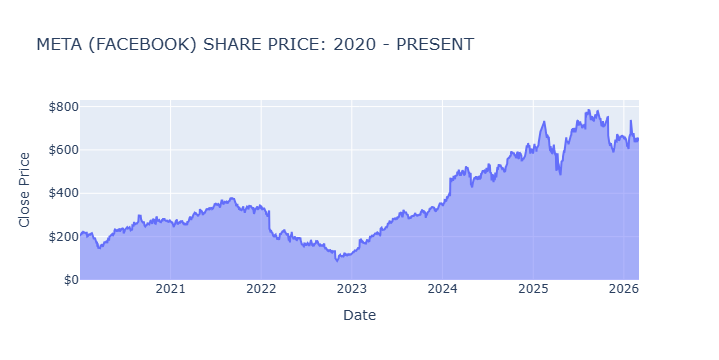

In [13]:
import yfinance as yf
import plotly.express as px
import datetime as dt

# 1. Fetch data from 2020 to TODAY
start = dt.datetime(2020, 1, 1)
end = dt.datetime.now()

# Download META (formerly FB)
df_meta = yf.download("META", start=start, end=end)

# 2. Create the Area chart
# We use df_meta['Close'] for the y-axis
area_chart = px.area(
    df_meta['Close'], 
    title='META (FACEBOOK) SHARE PRICE: 2020 - PRESENT'
)

# 3. Styling
area_chart.update_xaxes(title_text='Date')
area_chart.update_yaxes(title_text='Close Price', tickprefix='$')
area_chart.update_layout(showlegend=False)

area_chart.show()

[*********************100%***********************]  1 of 1 completed


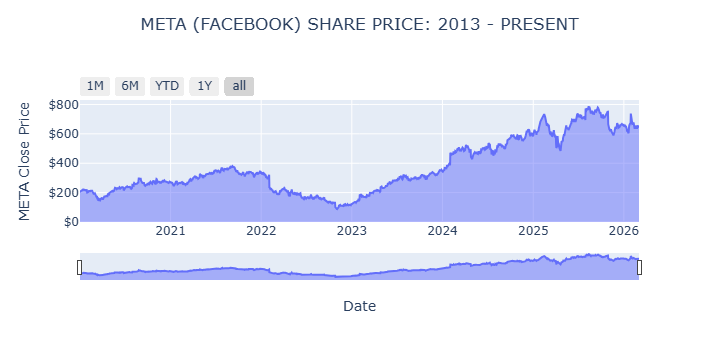

In [17]:
import yfinance as yf
import plotly.express as px
import datetime as dt

# 1. Fetch data up to the current date
# Starting from 2013 to show the full history including recent years
df_meta = yf.download("META", start="2020-01-01", end=dt.datetime.now())

# 2. Create the Area chart using 'Close' prices
c_area = px.area(df_meta['Close'], title = 'META (FACEBOOK) SHARE PRICE')

# 3. Add Customizations (Range Slider and Selector)
c_area.update_xaxes(
    title_text = 'Date',
    rangeslider_visible = True,
    rangeselector = dict(
        buttons = list([
            dict(count = 1, label = '1M', step = 'month', stepmode = 'backward'),
            dict(count = 6, label = '6M', step = 'month', stepmode = 'backward'),
            dict(count = 1, label = 'YTD', step = 'year', stepmode = 'todate'),
            dict(count = 1, label = '1Y', step = 'year', stepmode = 'backward'),
            dict(step = 'all')])))

# 4. Update Y-axis and Layout
c_area.update_yaxes(title_text = 'META Close Price', tickprefix = '$')
c_area.update_layout(
    showlegend = False,
    title = {
        'text': 'META (FACEBOOK) SHARE PRICE: 2013 - PRESENT',
        'y': 0.95,
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    }
)

c_area.show()

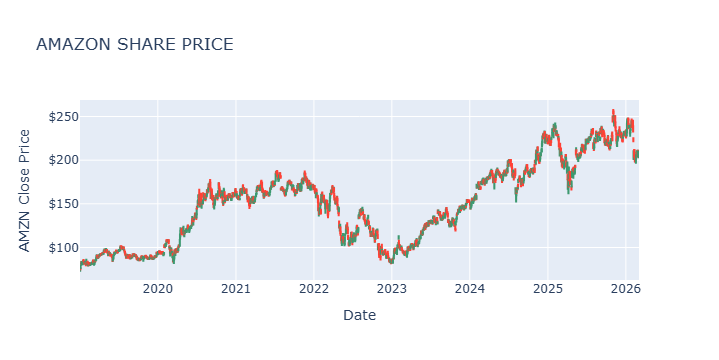

In [18]:
# candlestick chart

candlestick = go.Figure(data = [go.Candlestick(x = stocks.index, 
                                               open = stocks[('Open',    'AMZN')], 
                                               high = stocks[('High',    'AMZN')], 
                                               low = stocks[('Low',    'AMZN')], 
                                               close = stocks[('Close',    'AMZN')])])

candlestick.update_layout(xaxis_rangeslider_visible = False, title = 'AMAZON SHARE PRICE')
candlestick.update_xaxes(title_text = 'Date')
candlestick.update_yaxes(title_text = 'AMZN Close Price', tickprefix = '$')

candlestick.show()

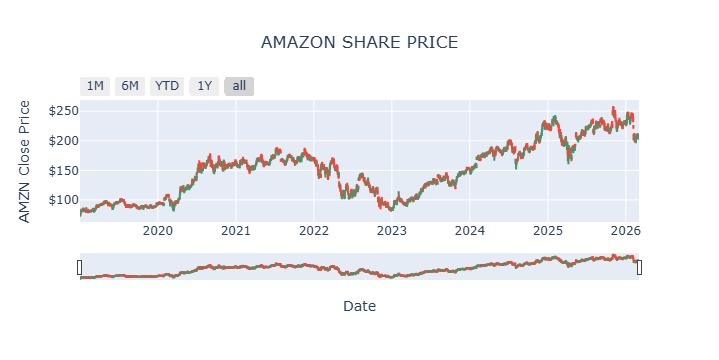

In [20]:
# Customized Candlestick

c_candlestick = go.Figure(data = [go.Candlestick(x = stocks.index, 
                                               open = stocks[('Open',    'AMZN')], 
                                               high = stocks[('High',    'AMZN')], 
                                               low = stocks[('Low',    'AMZN')], 
                                               close = stocks[('Close',    'AMZN')])])

c_candlestick.update_xaxes(
    title_text = 'Date',
    rangeslider_visible = True,
    rangeselector = dict(
        buttons = list([
            dict(count = 1, label = '1M', step = 'month', stepmode = 'backward'),
            dict(count = 6, label = '6M', step = 'month', stepmode = 'backward'),
            dict(count = 1, label = 'YTD', step = 'year', stepmode = 'todate'),
            dict(count = 1, label = '1Y', step = 'year', stepmode = 'backward'),
            dict(step = 'all')])))

c_candlestick.update_layout(
    title = {
        'text': 'AMAZON SHARE PRICE',
        'y':0.9,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})

c_candlestick.update_yaxes(title_text = 'AMZN Close Price', tickprefix = '$')
c_candlestick.show()

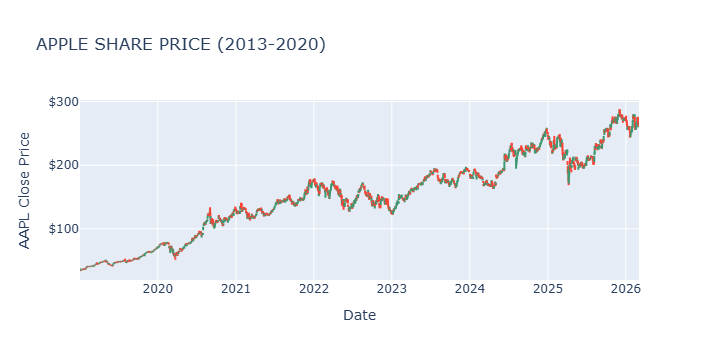

In [21]:
# OHLC chart

ohlc = go.Figure(data = [go.Ohlc(x = stocks.index, 
                                               open = stocks[('Open',    'AAPL')], 
                                               high = stocks[('High',    'AAPL')], 
                                               low = stocks[('Low',    'AAPL')], 
                                               close = stocks[('Close',    'AAPL')])])

ohlc.update_layout(xaxis_rangeslider_visible = False, title = 'APPLE SHARE PRICE (2013-2020)')
ohlc.update_xaxes(title_text = 'Date')
ohlc.update_yaxes(title_text = 'AAPL Close Price', tickprefix = '$')

ohlc.show()

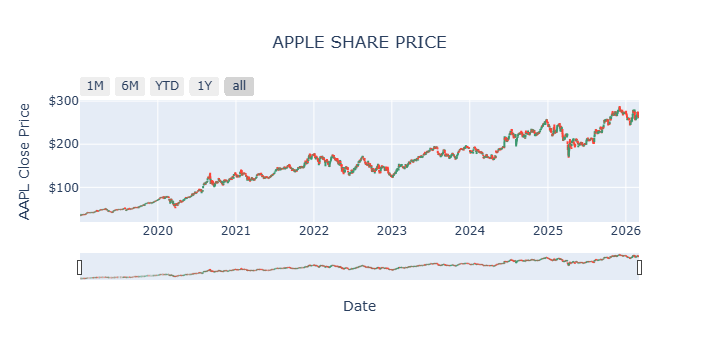

In [23]:
# Customized OHLC

c_ohlc = go.Figure(data = [go.Ohlc(x = stocks.index, 
                                               open = stocks[('Open',    'AAPL')], 
                                               high = stocks[('High',    'AAPL')], 
                                               low = stocks[('Low',    'AAPL')], 
                                               close = stocks[('Close',    'AAPL')])])

c_ohlc.update_xaxes(
    title_text = 'Date',
    rangeslider_visible = True,
    rangeselector = dict(
        buttons = list([
            dict(count = 1, label = '1M', step = 'month', stepmode = 'backward'),
            dict(count = 6, label = '6M', step = 'month', stepmode = 'backward'),
            dict(count = 1, label = 'YTD', step = 'year', stepmode = 'todate'),
            dict(count = 1, label = '1Y', step = 'year', stepmode = 'backward'),
            dict(step = 'all')])))

c_ohlc.update_layout(
    title = {
        'text': 'APPLE SHARE PRICE',
        'y':0.9,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'})
c_ohlc.update_yaxes(title_text = 'AAPL Close Price', tickprefix = '$')
c_ohlc.show()

[*********************100%***********************]  3 of 3 completed


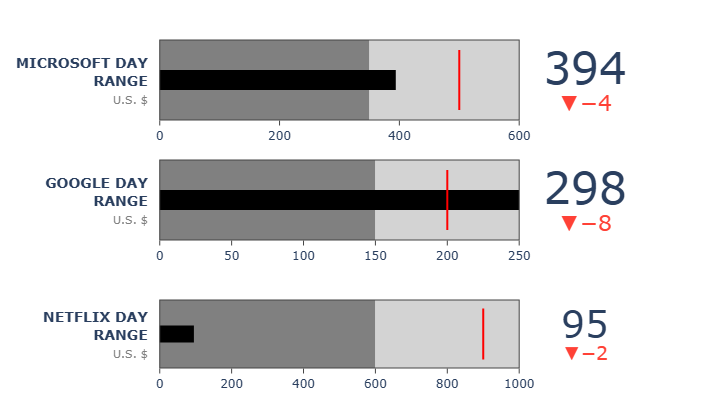

In [26]:
# 1. Download recent data (last 5 days is enough for value + delta)
tickers = ['NFLX', 'GOOGL', 'MSFT']
data = yf.download(tickers, period="5d")
stocks_close = data['Close']

# Function to get latest and previous price safely
def get_prices(ticker):
    latest = stocks_close[ticker].iloc[-1]
    previous = stocks_close[ticker].iloc[-2]
    return int(latest), int(previous)

nflx_now, nflx_prev = get_prices('NFLX')
googl_now, googl_prev = get_prices('GOOGL')
msft_now, msft_prev = get_prices('MSFT')

# 2. Create the Bullet Chart
c_bullet = go.Figure()

# NETFLIX (Current range ~800+)
c_bullet.add_trace(go.Indicator(
    mode = "number+gauge+delta", 
    value = nflx_now,
    delta = {'reference': nflx_prev},
    domain = {'x': [0.25, 1], 'y': [0.08, 0.25]},
    title = {'text':"<b>NETFLIX DAY<br>RANGE</b><br><span style='color: gray; font-size:0.8em'>U.S. $</span>", 
             'font': {"size": 14}},    
    gauge = {
        'shape': "bullet",
        'axis': {'range': [None, 1000]}, # Adjusted for current prices
        'threshold': {'line': {'color': "Red", 'width': 2}, 'thickness': 0.75, 'value': 900},
        'steps': [
            {'range': [0, 600], 'color': "gray"},
            {'range': [600, 1000], 'color': "lightgray"}],
        'bar': {'color': 'black'}}))

# GOOGLE (Current range ~170-190 after stock split)
c_bullet.add_trace(go.Indicator(
    mode = "number+gauge+delta", 
    value = googl_now,
    delta = {'reference': googl_prev},
    domain = {'x': [0.25, 1], 'y': [0.4, 0.6]},
    title = {'text':"<b>GOOGLE DAY<br>RANGE</b><br><span style='color: gray; font-size:0.8em'>U.S. $</span>", 
             'font': {"size": 14}},
    gauge = {
        'shape': "bullet",
        'axis': {'range': [None, 250]}, # Adjusted for post-split prices
        'threshold': {'line': {'color': "red", 'width': 2}, 'thickness': 0.75, 'value': 200},
        'steps': [
            {'range': [0, 150], 'color': "gray"},
            {'range': [150, 250], 'color': "lightgray"}],
        'bar': {'color': 'black'}}))

# MICROSOFT (Current range ~400+)
c_bullet.add_trace(go.Indicator(
    mode = "number+gauge+delta", 
    value = msft_now,
    delta = {'reference': msft_prev},
    domain = {'x': [0.25, 1], 'y': [0.7, 0.9]},
    title = {'text':"<b>MICROSOFT DAY<br>RANGE</b><br><span style='color: gray; font-size:0.8em'>U.S. $</span>", 
             'font': {"size": 14}},
    gauge = {
        'shape': "bullet",
        'axis': {'range': [None, 600]}, # Adjusted for current prices
        'threshold': {'line': {'color': "red", 'width': 2}, 'thickness': 0.75, 'value': 500},
        'steps': [
            {'range': [0, 350], 'color': "gray"},
            {'range': [350, 600], 'color': "lightgray"}],
        'bar': {'color': "black"}}))

c_bullet.update_layout(height = 400 , margin = {'t':0, 'b':0, 'l':0})
c_bullet.show()